# Week 13 — Ultrasound Doppler: velocity, aliasing, color flow, pulsed vs continuous wave

Moving blood scatters sound with a **frequency shift** proportional to its velocity component along the beam:
$$f_d=\frac{2f_0\,v\cos\theta}{c},$$
where $\theta$ is the angle between the beam and the flow. In this notebook:

1. the **angle dependence** (no signal at $90^\circ$, large errors at steep angles);
2. a **pulsed-wave (PW)** measurement sampled once per pulse, so the **pulse repetition frequency (PRF)** sets a **Nyquist velocity** and fast flow **aliases**;
3. a **spectrogram** of pulsatile flow with and without aliasing;
4. a **color Doppler** map of a curved vessel with a jet, showing red/blue direction coding, a zero band where the flow is perpendicular to the beam, and a mosaic when the jet aliases;
5. **continuous-wave (CW)** (all velocities along the beam, no depth information) vs PW (one depth).

Sign convention: positive velocity is **toward** the probe (shown red).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.ndimage import gaussian_filter

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(0)

c = 1540.0
f0 = 3.0e6

def doppler_shift(v, theta_deg, f0=f0):
    return 2 * f0 * v * np.cos(np.radians(theta_deg)) / c

def v_from_fd(fd, theta_deg, f0=f0):
    return fd * c / (2 * f0 * np.cos(np.radians(theta_deg)))

print(f"blood at 0.5 m/s, 60 deg, 3 MHz probe: Doppler shift = {doppler_shift(0.5, 60):.0f} Hz")
print(f"same flow, 0 deg: {doppler_shift(0.5, 0):.0f} Hz")

blood at 0.5 m/s, 60 deg, 3 MHz probe: Doppler shift = 974 Hz
same flow, 0 deg: 1948 Hz


## 1. Angle dependence

The shift follows $\cos\theta$. At $90^\circ$ the beam only sees flow **across** it, so there is no Doppler signal. Systems convert $f_d$ to velocity with an **angle correction**; if the operator's angle is off by $5^\circ$, the velocity estimate $v_{est}=v\cos\theta/\cos(\theta+5^\circ)$ is biased, and the bias grows quickly at steep angles.

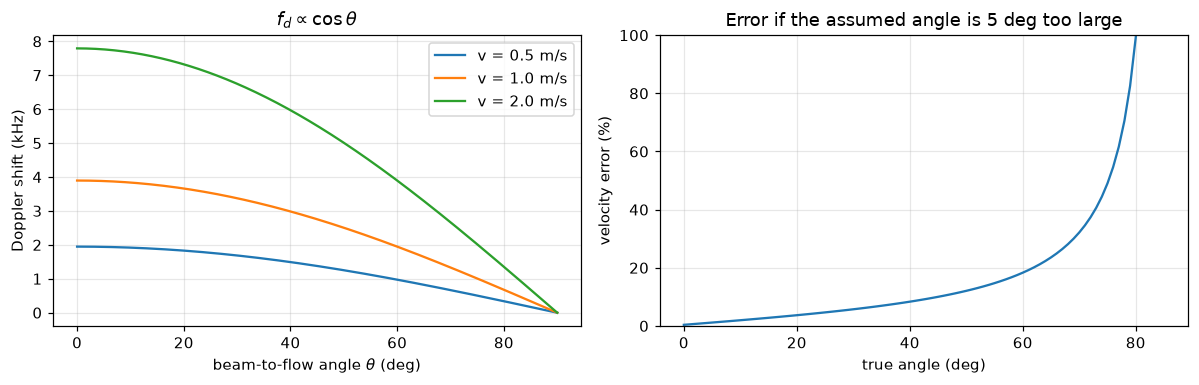

true angle  0 deg -> velocity error   0.4 %
true angle 20 deg -> velocity error   3.7 %
true angle 40 deg -> velocity error   8.3 %
true angle 60 deg -> velocity error  18.3 %
true angle 80 deg -> velocity error  99.2 %


In [2]:
th = np.linspace(0, 90, 361)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for v in (0.5, 1.0, 2.0):
    ax[0].plot(th, doppler_shift(v, th) / 1e3, label=f'v = {v} m/s')
ax[0].set(xlabel=r'beam-to-flow angle $\theta$ (deg)', ylabel='Doppler shift (kHz)', title=r'$f_d\propto\cos\theta$')
ax[0].legend()

ths = np.arange(0, 86, 1)
err = (np.cos(np.radians(ths)) / np.cos(np.radians(ths + 5)) - 1) * 100
ax[1].plot(ths, err)
ax[1].set(xlabel='true angle (deg)', ylabel='velocity error (%)', ylim=(0, 100),
          title='Error if the assumed angle is 5 deg too large')
plt.tight_layout(); plt.show()
for t in (0, 20, 40, 60, 80):
    e = (np.cos(np.radians(t)) / np.cos(np.radians(t + 5)) - 1) * 100
    print(f"true angle {t:2d} deg -> velocity error {e:5.1f} %")

## 2. Pulsed-wave Doppler: slow-time sampling and the Nyquist velocity

A pulsed system sends one pulse every $1/\text{PRF}$ seconds and keeps one sample (after demodulation) at the depth of interest. Over a pulse "ensemble" the sample sequence ("slow time") is a complex exponential at $f_d$, sampled at the PRF. Hence:

* the PRF acts as the sampling rate, so the unambiguous range is $|f_d|<\text{PRF}/2$, or $|v|<v_N=\dfrac{c\,\text{PRF}}{4f_0\cos\theta}$;
* but the pulse must reach depth $d$ and return before the next pulse is fired: $\text{PRF}_{max}=c/(2d)$.

So **deeper targets force a lower PRF and a lower Nyquist velocity**.

In [3]:
def slow_time(v, theta, prf, M=64, snr_db=20):
    fd = doppler_shift(v, theta)
    m = np.arange(M)
    s = np.exp(2j * np.pi * fd * m / prf)
    noise = (rng.normal(size=M) + 1j * rng.normal(size=M)) / np.sqrt(2)
    return s + noise * 10 ** (-snr_db / 20)

def kasai(s, prf, theta):
    """Lag-one autocorrelation (Kasai) velocity estimate."""
    R1 = np.sum(s[1:] * np.conj(s[:-1]))
    return v_from_fd(np.angle(R1) * prf / (2 * np.pi), theta)

def v_nyquist(prf, theta=0):
    return c * prf / (4 * f0 * np.cos(np.radians(theta)))

print(f"{'depth (cm)':>10s} {'PRF max (kHz)':>14s} {'v_N, 0 deg (m/s)':>17s} {'v_N, 60 deg (m/s)':>18s}")
for d_cm in (3, 6, 12, 20):
    prf = c / (2 * d_cm / 100)
    print(f"{d_cm:10d} {prf/1e3:14.2f} {v_nyquist(prf, 0):17.2f} {v_nyquist(prf, 60):18.2f}")

depth (cm)  PRF max (kHz)  v_N, 0 deg (m/s)  v_N, 60 deg (m/s)
         3          25.67              3.29               6.59
         6          12.83              1.65               3.29
        12           6.42              0.82               1.65
        20           3.85              0.49               0.99


### Aliasing sweep

At 12 cm depth the maximum PRF is about 6.4 kHz. We sweep the true velocity (probe at $30^\circ$ to the flow) and estimate it from the slow-time ensemble. Above $v_N$ the estimate wraps around to the opposite sign, which is **aliasing**; it follows
$$v_{est}=\big((v+v_N)\bmod 2v_N\big)-v_N .$$

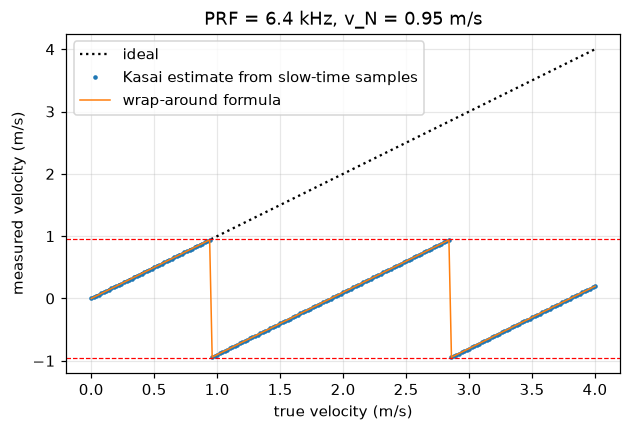

max |estimate - wrap formula| = 0.001 m/s


In [4]:
d = 0.12
prf = c / (2 * d)
theta_b = 30
vN = v_nyquist(prf, theta_b)
v_true = np.linspace(0, 4, 201)
v_est = np.array([kasai(slow_time(v, theta_b, prf, M=64, snr_db=25), prf, theta_b) for v in v_true])
v_wrap = (v_true + vN) % (2 * vN) - vN

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(v_true, v_true, 'k:', label='ideal')
ax.plot(v_true, v_est, '.', ms=4, label='Kasai estimate from slow-time samples')
ax.plot(v_true, v_wrap, '-', lw=1, label='wrap-around formula')
ax.axhline(vN, color='r', ls='--', lw=0.8); ax.axhline(-vN, color='r', ls='--', lw=0.8)
ax.set(xlabel='true velocity (m/s)', ylabel='measured velocity (m/s)',
       title=f'PRF = {prf/1e3:.1f} kHz, v_N = {vN:.2f} m/s')
ax.legend(); plt.show()
print(f"max |estimate - wrap formula| = {np.abs(v_est - v_wrap)[np.abs(np.abs(v_true) % (2*vN) - vN) > 0.1].max():.3f} m/s")

## 3. Spectrogram of pulsatile flow

PW Doppler displays a **spectrogram**: velocity vs time over a heartbeat. Here the velocity follows a systolic spike plus low diastolic flow (beat period 0.8 s, peak 1.6 m/s, probe at $30^\circ$). With a high PRF the whole waveform is shown; with a low PRF the systolic peak wraps to negative velocities.

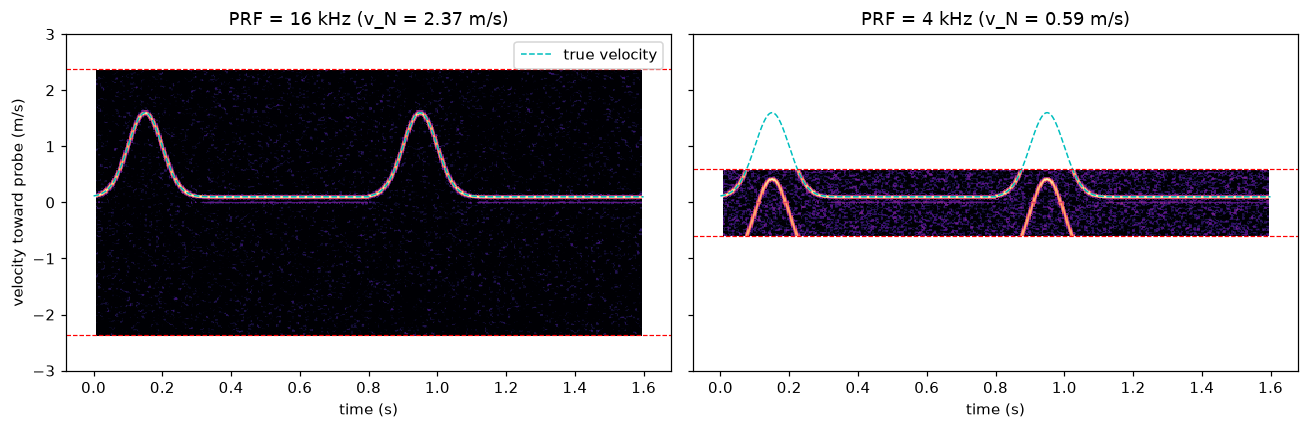

In [5]:
def v_of_t(t, T=0.8, vpk=1.5):
    ph = t % T
    return 0.1 + vpk * np.exp(-((ph - 0.15) / 0.07) ** 2)

def simulate_pw(prf, dur=1.6, theta=30, snr_db=15):
    t = np.arange(int(dur * prf)) / prf
    fd = doppler_shift(v_of_t(t), theta)
    s = np.exp(2j * np.pi * np.cumsum(fd) / prf)
    s = s + (rng.normal(size=t.size) + 1j * rng.normal(size=t.size)) / np.sqrt(2) * 10 ** (-snr_db / 20)
    return t, s

theta_s = 30
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (prf_s, nper) in zip(axs, [(16000, 256), (4000, 64)]):
    t, s = simulate_pw(prf_s, theta=theta_s)
    f, tt, S = signal.spectrogram(s, fs=prf_s, nperseg=nper, noverlap=nper * 3 // 4, window='hann',
                                  return_onesided=False, mode='psd')
    f = np.fft.fftshift(f); S = np.fft.fftshift(S, axes=0)
    vax = v_from_fd(f, theta_s)
    db = 10 * np.log10(S / S.max() + 1e-12)
    ax.pcolormesh(tt, vax, np.maximum(db, -35), cmap='magma', shading='auto', vmin=-35, vmax=0)
    ax.plot(t, v_of_t(t), 'c--', lw=1, label='true velocity')
    vN_s = v_nyquist(prf_s, theta_s)
    ax.axhline(vN_s, color='r', ls='--', lw=0.8); ax.axhline(-vN_s, color='r', ls='--', lw=0.8)
    ax.set(title=f'PRF = {prf_s/1e3:.0f} kHz (v_N = {vN_s:.2f} m/s)', xlabel='time (s)', ylim=(-3, 3)); ax.grid(False)
axs[0].set_ylabel('velocity toward probe (m/s)'); axs[0].legend(loc='upper right')
plt.tight_layout(); plt.show()

Raising the PRF, lowering $f_0$, or using a **larger angle** (smaller $\cos\theta$) all raise the velocity limit; if none is enough, **continuous-wave** Doppler has no PRF limit but loses depth information (section 5).

## 4. Color Doppler of a curved vessel with a jet

Color Doppler estimates one velocity per pixel (Kasai-style, from a short ensemble) and overlays it on the gray B-mode. The vessel below is an **arch** with flow from left to right, and the beam runs straight down from the top. The left limb moves **toward** the probe (red), the right limb **away** (blue), and at the top, where flow is **perpendicular** to the beam, the shift is zero. A **jet** is added to the left limb. With a low Nyquist limit the jet wraps to the opposite color, a mosaic.

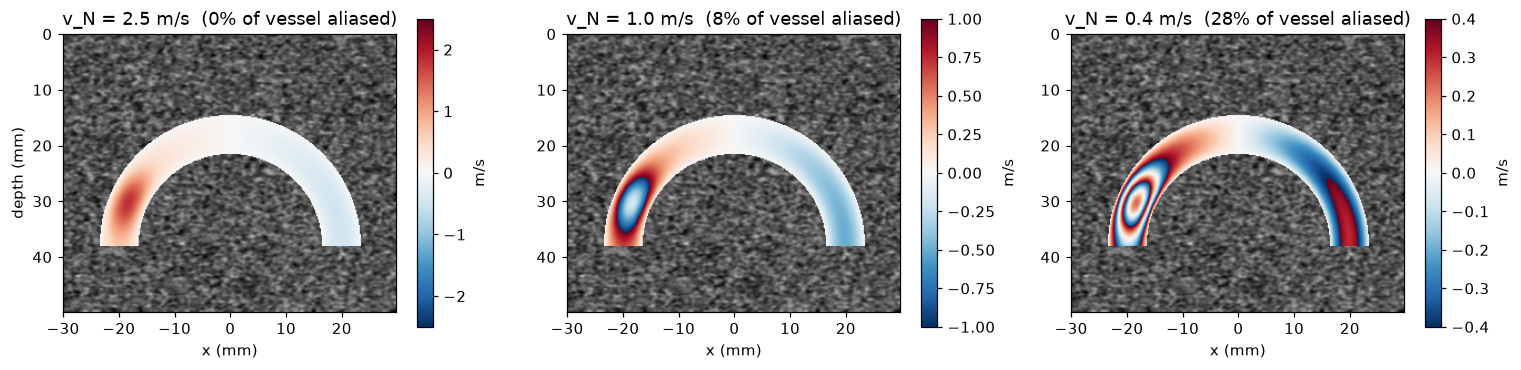

peak velocity toward the probe in the jet: 1.83 m/s


In [6]:
H, W, px = 250, 300, 0.2                       # pixel size 0.2 mm
xs = (np.arange(W) - W / 2) * px
zs = np.arange(H) * px
X, Z = np.meshgrid(xs, zs)
cx, cz, R, wv = 0.0, 38.0, 20.0, 3.5          # arch centre, radius, half-width (mm)
DX, DZ = X - cx, Z - cz
rho = np.hypot(DX, DZ)
vessel = (np.abs(rho - R) < wv) & (DZ <= 0)
profile = np.clip(1 - ((rho - R) / wv) ** 2, 0, 1)     # parabolic cross-section
tx = -DZ / np.maximum(rho, 1e-9)                       # unit tangent (flow: left -> over the top -> right)
tz = DX / np.maximum(rho, 1e-9)
speed = 0.5 * (1 + 3 * np.exp(-((X + 18) ** 2 + (Z - 30) ** 2) / (2 * 4 ** 2))) * profile * vessel
v_toward = -(speed * tz)                               # beam points +z; toward the probe is -z

def wrap(v, vN):
    return (v + vN) % (2 * vN) - vN

bg = gaussian_filter(rng.rayleigh(1, (H, W)), (1, 1.5))
bg = (bg - bg.min()) / np.ptp(bg)

fig, axs = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, vN in zip(axs, (2.5, 1.0, 0.4)):
    ax.imshow(bg, cmap='gray', extent=[xs[0], xs[-1], zs[-1], zs[0]], vmin=0, vmax=1.3)
    col = np.ma.masked_where(~vessel, wrap(v_toward, vN))
    im = ax.imshow(col, cmap='RdBu_r', vmin=-vN, vmax=vN, extent=[xs[0], xs[-1], zs[-1], zs[0]])
    frac = np.mean(np.abs(v_toward[vessel]) > vN) * 100
    ax.set(title=f'v_N = {vN} m/s  ({frac:.0f}% of vessel aliased)', xlabel='x (mm)'); ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.7, label='m/s')
axs[0].set_ylabel('depth (mm)')
plt.tight_layout(); plt.show()
print(f"peak velocity toward the probe in the jet: {v_toward.max():.2f} m/s")

## 5. Continuous-wave vs pulsed-wave Doppler

Three blood pools lie along the same beam at 3, 6, and 9 cm, moving at 0.2, 0.6, and 1.1 m/s (beam parallel to flow). **CW** transmits and receives continuously, so the received Doppler signal is the **sum of all velocities along the beam** (no depth information, but no PRF limit). **PW** keeps one range-gated sample per pulse, here at 6 cm, so only that depth contributes. (Idealization: we model the range gate as selecting a single depth's signal and ignore the finite gate length.)

Doppler shifts (Hz): [ 779. 2338. 4286.]


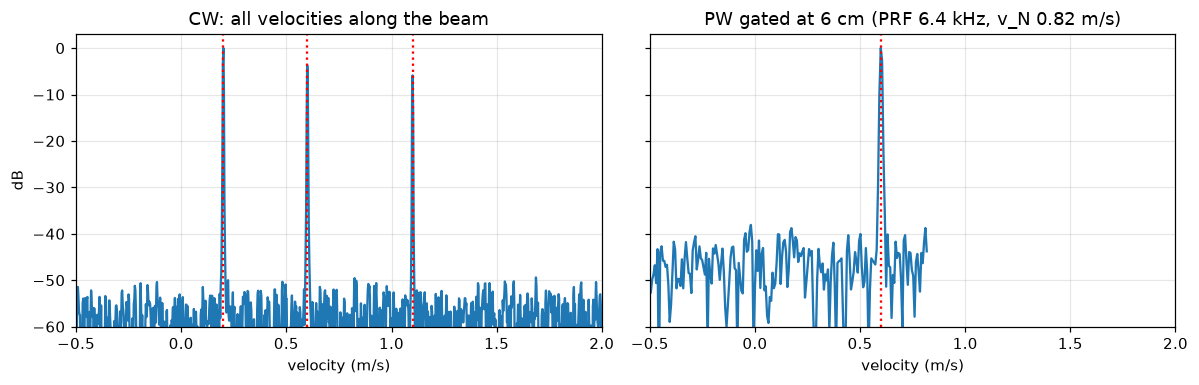

In [7]:
depths = np.array([0.03, 0.06, 0.09])
vels = np.array([0.2, 0.6, 1.1])
amps = np.array([1.0, 0.7, 0.5])                 # weaker echoes from deeper pools
fd = doppler_shift(vels, 0)
print("Doppler shifts (Hz):", np.round(fd))

def noise(n, level=0.05):
    return (rng.normal(size=n) + 1j * rng.normal(size=n)) / np.sqrt(2) * level

# CW: continuously sampled demodulated signal containing all three
fs_cw = 20000
n = 2048
t = np.arange(n) / fs_cw
cw = sum(a * np.exp(2j * np.pi * f * t) for a, f in zip(amps, fd)) + noise(n)
Fcw = np.fft.fftshift(np.fft.fft(cw * np.hanning(n)))
vax_cw = v_from_fd(np.fft.fftshift(np.fft.fftfreq(n, 1 / fs_cw)), 0)

# PW: range-gated at 6 cm, one sample per pulse
prf = c / (2 * 0.12)
m = 256
tm = np.arange(m) / prf
pw = amps[1] * np.exp(2j * np.pi * fd[1] * tm) + noise(m)
Fpw = np.fft.fftshift(np.fft.fft(pw * np.hanning(m)))
vax_pw = v_from_fd(np.fft.fftshift(np.fft.fftfreq(m, 1 / prf)), 0)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ax[0].plot(vax_cw, 20 * np.log10(np.abs(Fcw) / np.abs(Fcw).max() + 1e-6))
for v in vels: ax[0].axvline(v, color='r', ls=':')
ax[0].set(xlim=(-0.5, 2), ylim=(-60, 3), xlabel='velocity (m/s)', ylabel='dB', title='CW: all velocities along the beam')
ax[1].plot(vax_pw, 20 * np.log10(np.abs(Fpw) / np.abs(Fpw).max() + 1e-6))
ax[1].axvline(vels[1], color='r', ls=':')
ax[1].set(xlim=(-0.5, 2), xlabel='velocity (m/s)', title=f'PW gated at 6 cm (PRF {prf/1e3:.1f} kHz, v_N {v_nyquist(prf):.2f} m/s)')
plt.tight_layout(); plt.show()

## Summary

* $f_d=2f_0v\cos\theta/c$: **no signal at $90^\circ$**; angle-correction errors grow with $\theta$.
* **PW** Doppler resolves **depth** but samples once per pulse, so $v_N=c\,\text{PRF}/(4f_0\cos\theta)$ and $\text{PRF}\le c/2d$: deep, fast flow **aliases** (the colors wrap and form a mosaic jet).
* **CW** Doppler has no aliasing limit but **no range resolution**.
* Remedies for aliasing: higher PRF, lower $f_0$, larger angle, or CW.

Related notebooks: [Ultrasound_MMode](../Week12/Ultrasound_MMode.ipynb) (motion over time) and [Ultrasound_Beamforming_Aperture](Ultrasound_Beamforming_Aperture.ipynb).